# Employee Attrition Flight-Risk Prediction — Machine Learning Project
**Team:** Gabriel Jaycee Near, Geitth Andrew Lamasan, John Vincent Wilson, Paul Brian Ticar  
**Date:** November 19, 2026 (Checkpoint: Stages B, C, and D)  

**Summary:** Using 1,470 employee records and demographic, commute, and travel attributes, we frame employee attrition (`Attrition`: `Yes` vs. `No`) as an imbalanced binary classification task (~16.1% attrition) to help HR prioritize targeted retention outreach. All preprocessing steps are encapsulated inside scikit-learn `Pipeline`s and evaluated via 5-fold stratified cross-validation on the training set against a naive baseline, while the 25% test set remains untouched until Stage E.

## Problem Definition
### Problem Framing, Target, and Evaluation Metrics (`A1`–`A7`)
* **Real-World Problem (`A1`):** Voluntary employee turnover increases hiring, onboarding, and productivity costs. Predicting attrition flight risk enables HR teams to focus proactive retention interventions on high-risk employees.
* **Task Type & Target (`A2`, `A3`):** Binary classification predicting `Attrition` (`1` = `Yes`, `0` = `No`) from employee demographic, travel, and role-level attributes.
* **Metrics & Error Cost (`A4`):** Because `Attrition` is imbalanced (~16.1% `Yes` vs. ~83.9% `No`), raw accuracy is misleading. We track **ROC-AUC** (threshold-independent ranking), **PR-AUC** (focused on the minority positive class), and **F1-score** (balancing missed leavers/false negatives against unnecessary retention outreach/false positives).
* **Baseline (`A7`):** A naive majority-class baseline (`DummyClassifier(strategy="most_frequent")`) predicts `"No"` for all employees, achieving ~83.9% accuracy, `0.500` ROC-AUC, `0.162` PR-AUC, and `0.000` F1-score.

Below, we import required packages, set and print `SEED = 77` for reproducibility, and display package versions.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    f1_score,
)

SEED = 77
random.seed(SEED)
np.random.seed(SEED)

print(f"Random Seed: {SEED}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | numpy: {np.__version__} | scikit-learn: {sklearn.__version__}")

sns.set_theme(style="ticks", palette="viridis")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

Random Seed: 77
Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | scikit-learn: 1.6.1


**Output Interpretation:** `SEED = 77` and exact library versions (`Python 3.13.18`, `pandas 2.2.3`, `numpy 2.4.6`, `scikit-learn 1.6.1`) are fixed and logged for top-to-bottom reproducibility.

Next, we load `WA_Fn-UseC_-HR-Employee-Attrition-selected-columns.csv` using a relative path and inspect its dimensions and sample rows.

In [ ]:
DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition-selected-columns.csv"
raw_df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
display(raw_df.head())

Dataset Shape: 1470 rows, 10 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7


**Output Interpretation:** The dataset loads cleanly with **1,470 rows and 10 columns** (`Age`, `Attrition`, `BusinessTravel`, `DailyRate`, `Department`, `DistanceFromHome`, `Education`, `EducationField`, `EmployeeCount`, and `EmployeeNumber`).

---

## Summarize and Analyze Data
### Data Dictionary, Quality Audit, and Target Distribution (`B1`, `B2`, `B3`)
| Column | Meaning & Units | Raw Type | Allowed / Observed Range | Modeling Treatment |
| :--- | :--- | :--- | :--- | :--- |
| `Age` | Employee age in years | Integer | `18` to `60` | Numeric (continuous) |
| `Attrition` | Whether the employee left the company (`Yes` / `No`) | Object | `{No, Yes}` | Binary target (`1` = `Yes`, `0` = `No`) |
| `BusinessTravel` | Frequency of work-related travel | Object | `{Non-Travel, Travel_Rarely, Travel_Frequently}` | Categorical (one-hot encoded) |
| `DailyRate` | Daily billing/pay rate index (currency units/day) | Integer | `102` to `1499` | Numeric (continuous) |
| `Department` | Organizational department | Object | `{Sales, Research & Development, Human Resources}` | Categorical (one-hot encoded) |
| `DistanceFromHome` | Commute distance from home to workplace (miles/km) | Integer | `1` to `29` | Numeric (discrete count) |
| `Education` | Highest education level (`1`=Below College to `5`=Doctor) | Integer | `1` to `5` | Numeric (discrete ordinal) |
| `EducationField` | Academic field of study | Object | `{Life Sciences, Medical, Marketing, Technical Degree, Human Resources, Other}` | Categorical (one-hot encoded) |
| `EmployeeCount` | Constant headcount indicator per row | Integer | `1` (single unique value) | Dropped (zero variance) |
| `EmployeeNumber` | Unique employee identifier | Integer | `1` to `2068` (1,470 unique values) | Dropped (arbitrary ID) |

*(No date or free-text columns exist in this 10-column dataset.)*

Below, we audit data types, missing counts, duplicates, numeric ranges, and class balance.

## Summarize and Analyze Data
### Data Dictionary, Quality Audit, and Target Distribution (`B1`, `B2`, `B3`)
Below, we audit data types, missing counts, duplicates, numeric ranges, and class balance.

In [ ]:
audit_df = pd.DataFrame({
    "Data_Type": raw_df.dtypes,
    "Missing_Count": raw_df.isnull().sum(),
    "Missing_Pct": raw_df.isnull().mean() * 100,
    "Unique_Values": raw_df.nunique(dropna=False),
})

num_summary = raw_df.select_dtypes(include="number").describe().T[["count", "mean", "std", "min", "50%", "max"]]
audit_full = audit_df.join(num_summary)

print("=== COLUMN AUDIT & NUMERIC SUMMARY ===")
display(audit_full)

print(f"Duplicate rows: {raw_df.duplicated().sum()}")
print(f"Duplicate EmployeeNumber values: {raw_df['EmployeeNumber'].duplicated().sum()}")

target_counts = raw_df["Attrition"].value_counts(dropna=False)
target_pct = raw_df["Attrition"].value_counts(normalize=True) * 100
print("\n=== TARGET DISTRIBUTION (Attrition) ===")
display(pd.DataFrame({"Count": target_counts, "Percentage": target_pct}))

=== COLUMN AUDIT & NUMERIC SUMMARY ===


,Data_Type,Missing_Count,Missing_Pct,Unique_Values,count,mean,std,min,50%,max
Age,int64,0,0.000,43,1470.000,36.924,9.135,18.000,36.000,60.000
Attrition,object,0,0.000,2,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,object,0,0.000,3,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,int64,0,0.000,886,1470.000,802.486,403.509,102.000,802.000,1499.000
Department,object,0,0.000,3,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,int64,0,0.000,29,1470.000,9.193,8.107,1.000,7.000,29.000
Education,int64,0,0.000,5,1470.000,2.913,1.024,1.000,3.000,5.000
EducationField,object,0,0.000,6,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,int64,0,0.000,1,1470.000,1.000,0.000,1.000,1.000,1.000
EmployeeNumber,int64,0,0.000,1470,1470.000,1024.865,602.024,1.000,1020.500,2068.000


Duplicate rows: 0
Duplicate EmployeeNumber values: 0

=== TARGET DISTRIBUTION (Attrition) ===


,Count,Percentage
Attrition,,
No,1233,83.878
Yes,237,16.122


**Output Interpretation (`B2`, `B3`):**
* **Missing & Duplicated Values (`B2`):** There are `0` missing values across all 10 columns, `0` duplicate rows, and `0` duplicate `EmployeeNumber` values. All numeric ranges (`Age`: 18–60, `DailyRate`: 102–1499, `DistanceFromHome`: 1–29, `Education`: 1–5) are valid with no impossible values.
* **Target Distribution (`B3`):** `1,233` employees (`83.878%`) stayed (`No`) and `237` (`16.122%`) left (`Yes`). This ~5.2:1 class imbalance requires **stratified splitting** and imbalance-sensitive metrics (**ROC-AUC**, **PR-AUC**, **F1**).

### Exploratory Visualizations, Correlations, Hypothesis, and Leakage Check (`B4`, `B5`, `B6`, `B7`)
We next visualize attrition rates across categorical attributes, compare numeric distributions by `Attrition`, and inspect feature-to-feature correlations.

### Exploratory Visualizations, Correlations, Hypothesis, and Leakage Check (`B4`, `B5`, `B6`, `B7`)
We next visualize attrition rates across categorical attributes, compare numeric distributions by `Attrition`, and inspect feature-to-feature correlations.

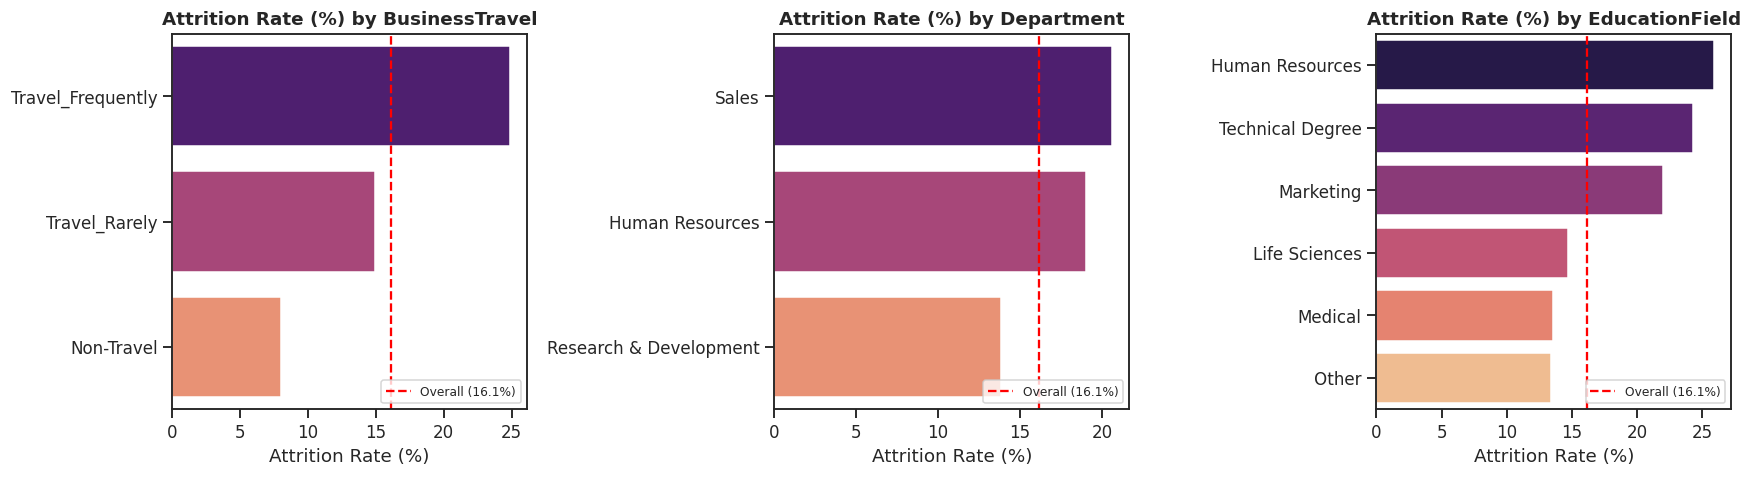

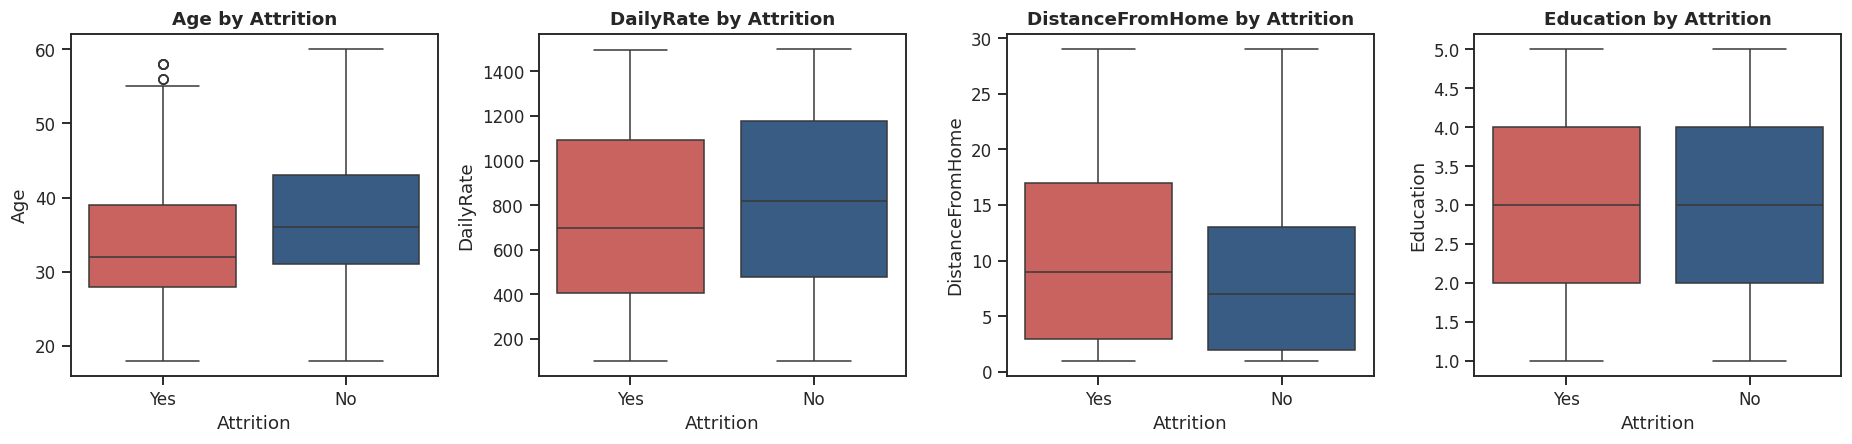

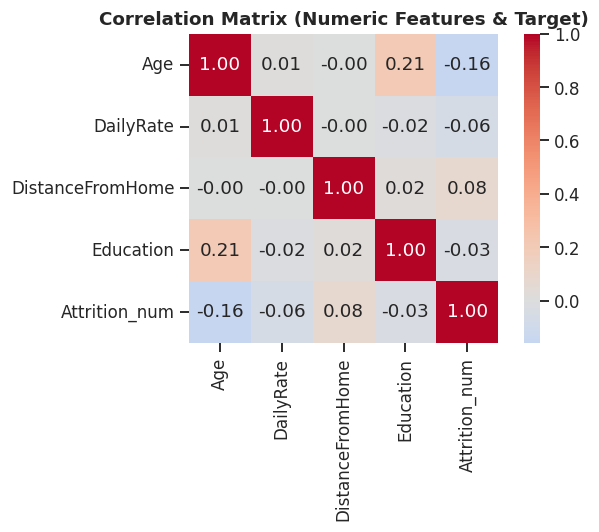

In [ ]:
cat_cols_eda = ["BusinessTravel", "Department", "EducationField"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
overall_rate = (raw_df["Attrition"] == "Yes").mean() * 100

for idx, col in enumerate(cat_cols_eda):
    rates = (
        raw_df.groupby(col)["Attrition"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )
    sns.barplot(x=rates.values, y=rates.index, ax=axes[idx], palette="magma")
    axes[idx].axvline(overall_rate, color="red", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
    axes[idx].set_title(f"Attrition Rate (%) by {col}", fontweight="bold")
    axes[idx].set_xlabel("Attrition Rate (%)")
    axes[idx].set_ylabel("")
    axes[idx].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

num_cols_eda = ["Age", "DailyRate", "DistanceFromHome", "Education"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for idx, col in enumerate(num_cols_eda):
    sns.boxplot(data=raw_df, x="Attrition", y=col, ax=axes[idx], palette={"No": "#2b5c8f", "Yes": "#d9534f"})
    axes[idx].set_title(f"{col} by Attrition", fontweight="bold")
    axes[idx].set_xlabel("Attrition")

plt.tight_layout()
plt.show()

corr_df = raw_df[["Age", "DailyRate", "DistanceFromHome", "Education"]].copy()
corr_df["Attrition_num"] = raw_df["Attrition"].map({"Yes": 1, "No": 0})
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix (Numeric Features & Target)", fontweight="bold")
plt.tight_layout()
plt.show()

**Output Interpretation (`B4`, `B5`, `B6`, `B7`):**
* **Features Related to Target (`B4`):** `BusinessTravel` shows the clearest categorical separation (`Travel_Frequently` exhibits markedly higher attrition than `Non-Travel`), `Department` shows higher attrition in `Sales` and `Human Resources` than `Research & Development`, and `Age` shows the strongest numeric correlation with attrition ($r = -0.16$), with younger employees leaving more often.
* **Multicollinearity (`B5`):** Pairwise linear correlations among raw numeric features (`Age`, `DailyRate`, `DistanceFromHome`, `Education`) are weak ($|r| \le 0.21$), indicating no severe redundancy among original numeric columns.
* **Hypothesis to Test (`B6`):** Although `DistanceFromHome` has a modest standalone correlation with attrition ($r = +0.08$), long commutes may disproportionately affect younger or lower-paid employees. We hypothesize that interaction features combining commute distance with daily rate and age (`Commute_to_Rate_Ratio` and `Age_Distance_Product`) will improve cross-validated ROC-AUC and PR-AUC—which we will test via ablation in Stage E.
* **Leakage Check (`B7`):** No feature shows suspiciously high target correlation ($|r| \le 0.16$), `EmployeeNumber` is excluded, and no post-outcome HR fields are present.

---

## Prepare Data
### Cleaning, Feature Engineering, Stratified Split, and Leakage-Safe Pipeline (`C1`–`C6`)
* **Cleaning & Feature Decisions (`C1`, `C4`):** We drop `EmployeeCount` (constant `1`, zero variance) and `EmployeeNumber` (unique ID) to prevent memorization. We engineer two row-wise interaction features from pre-existing attributes: `Commute_to_Rate_Ratio = DistanceFromHome / (DailyRate + 1)` and `Age_Distance_Product = Age * DistanceFromHome`.
* **Train/Test Split (`C2`):** We apply a stratified 75%/25% split (`1,102` train, `368` test, `random_state=77`, `stratify=y`). `X_test` is strictly held out and untouched throughout Stages B–D.
* **Leakage Prevention & Transforms (`C3`, `C5`):** Median imputation + `StandardScaler` (numeric) and most-frequent imputation + `OneHotEncoder(drop="first", handle_unknown="ignore")` (categorical) are placed inside a `ColumnTransformer` + `Pipeline` so parameters are learned exclusively from training folds. Scaling is required for linear, kernel (SVC), and neural (MLP) models, whereas tree ensembles are scale-invariant.
* **Prediction-Time Availability (`C6`):** All selected features are standard HR attributes available prior to an employee's turnover decision.